/tmp/ipykernel_5660/2397598670.py:5: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('../data/final_metropole/Merge_final_2.csv')


(19968, 81)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


DatetimeIndex(['2021-01-04', '2021-01-11', '2021-01-18', '2021-01-25',
               '2021-02-01', '2021-02-08', '2021-02-15', '2021-02-22',
               '2021-03-01', '2021-03-08',
               ...
               '2024-10-21', '2024-10-28', '2024-11-04', '2024-11-11',
               '2024-11-18', '2024-11-25', '2024-12-02', '2024-12-09',
               '2024-12-16', '2024-12-23'],
              dtype='datetime64[us]', name='date_semaine', length=208, freq=None)


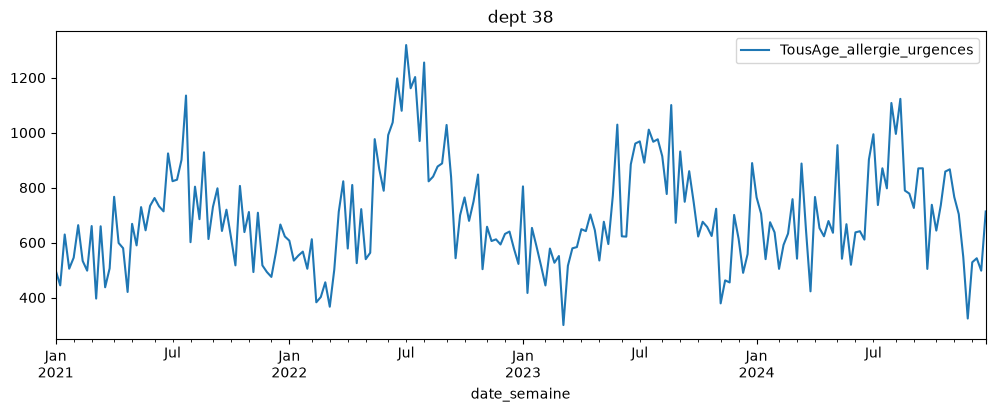

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../data/final_metropole/Merge_final_2.csv')

display(df.shape)
display(df.head())

s38 = df.loc[df["code_dept"] == "38"]
dates = pd.to_datetime(s38["date_semaine"] + "-1", format="%G-S%V-%u")
s38 = s38.set_index(dates)[["TousAge_allergie_urgences"]]
print(s38.index)

s38.plot(figsize=(12, 4));   
plt.title("dept 38");

In [31]:
annee = s38.index.year
train = s38[annee <= 2022]
val   = s38[annee == 2023]
test  = s38[annee == 2024]
print(len(train), len(val), len(test)) 


104 52 52


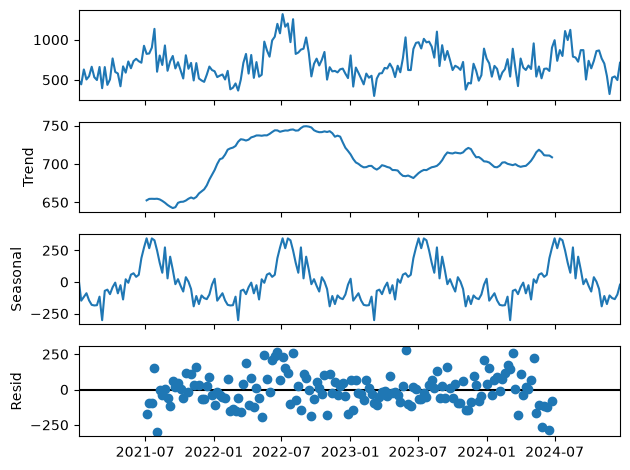

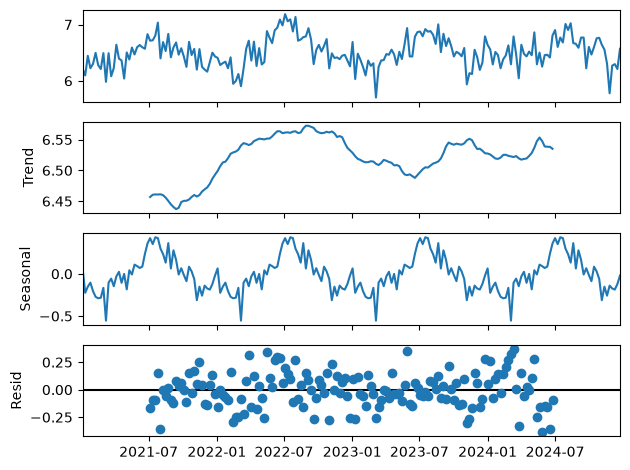

In [32]:
from statsmodels.tsa.seasonal import seasonal_decompose

res = seasonal_decompose(s38)
res.plot()
plt.show()

res = seasonal_decompose(np.log(s38))
res.plot()
plt.show()

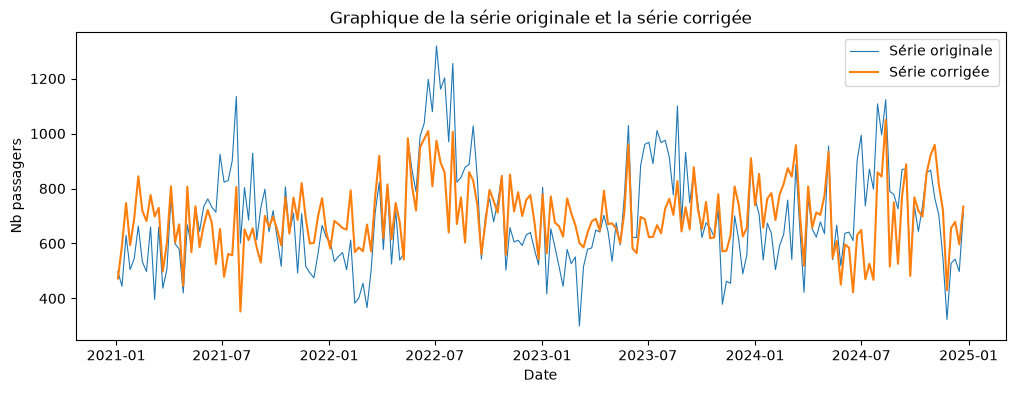

In [41]:
mult = seasonal_decompose(s38)
# On soustrait les coefficients saisonniers à la série airpasslog
cvs = s38['TousAge_allergie_urgences'] - mult.seasonal

plt.figure(figsize=(12, 4))
plt.plot(s38, label='Série originale', linewidth=0.8)
plt.plot(cvs, label='Série corrigée')
plt.title('Graphique de la série originale et la série corrigée')
plt.xlabel('Date')
plt.ylabel('Nb passagers')
plt.legend()
plt.show();